In [1]:
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler

In [2]:
train = pd.read_csv("../data/train.csv")
test = pd.read_csv("../data/test.csv")

print("Training compounds:", len(train))
print("Testing compounds:", len(test))

Training compounds: 1349
Testing compounds: 338


In [3]:
# Select the nine molecular descriptors
features = [
    "molecular_weight",
    "logp",
    "hba",
    "hbd",
    "psa",
    "rtb",
    "ro5_violations",
    "aromatic_rings",
    "heavy_atoms"
]

# Separate input features (X) and target variable (y)
X_train = train[features]
y_train = train["pf_pEC50"]

X_test = test[features]
y_test = test["pf_pEC50"]

# Check the dimensions
print("Training features:", X_train.shape)
print("Testing features:", X_test.shape)
print("Training target:", y_train.shape)
print("Testing target:", y_test.shape)

Training features: (1349, 9)
Testing features: (338, 9)
Training target: (1349,)
Testing target: (338,)


In [4]:
# Create a Linear Regression model with feature scaling
model = make_pipeline(
    StandardScaler(),
    LinearRegression()
)

# Train the model using training data only
model.fit(X_train, y_train)

print("Linear Regression model trained successfully!")

Linear Regression model trained successfully!


In [5]:
from sklearn.model_selection import KFold, cross_validate

# Create 5-fold cross-validation
cv = KFold(
    n_splits=5,
    shuffle=True,
    random_state=42
)

# Evaluate using ONLY the training dataset
cv_results = cross_validate(
    model,
    X_train,
    y_train,
    cv=cv,
    scoring={
        "r2": "r2",
        "rmse": "neg_root_mean_squared_error"
    }
)

# Extract scores for each fold
cv_r2 = cv_results["test_r2"]
cv_rmse = -cv_results["test_rmse"]

# Display results
print("5-FOLD CROSS-VALIDATION RESULTS")
print("--------------------------------")
print(f"Mean R²: {cv_r2.mean():.3f}")
print(f"R² standard deviation: {cv_r2.std():.3f}")
print(f"Mean RMSE: {cv_rmse.mean():.3f}")
print(f"RMSE standard deviation: {cv_rmse.std():.3f}")

5-FOLD CROSS-VALIDATION RESULTS
--------------------------------
Mean R²: 0.022
R² standard deviation: 0.032
Mean RMSE: 0.545
RMSE standard deviation: 0.047


In [9]:
# Predict pEC50 values for the training compounds
train_predictions = model.predict(X_train)

# Calculate training performance
train_r2 = r2_score(y_train, train_predictions)
train_rmse = np.sqrt(mean_squared_error(y_train, train_predictions))
train_mae = mean_absolute_error(y_train, train_predictions)

print("TRAINING SET PERFORMANCE")
print("-------------------------")
print(f"R²:   {train_r2:.3f}")
print(f"RMSE: {train_rmse:.3f}")
print(f"MAE:  {train_mae:.3f}")

TRAINING SET PERFORMANCE
-------------------------
R²:   0.046
RMSE: 0.541
MAE:  0.386


In [6]:
# Make predictions on the test set
test_predictions = model.predict(X_test)

# Optional: also compute MAE for reporting
from sklearn.metrics import mean_absolute_error

test_mae = mean_absolute_error(y_test, test_predictions)

print("Final Test Set Performance")
print("--------------------------")
print(f"R²:   {r2_score(y_test, test_predictions):.3f}")
print(f"RMSE: {np.sqrt(mean_squared_error(y_test, test_predictions)):.3f}")
print(f"MAE:  {test_mae:.3f}")

Final Test Set Performance
--------------------------
R²:   0.044
RMSE: 0.570
MAE:  0.403


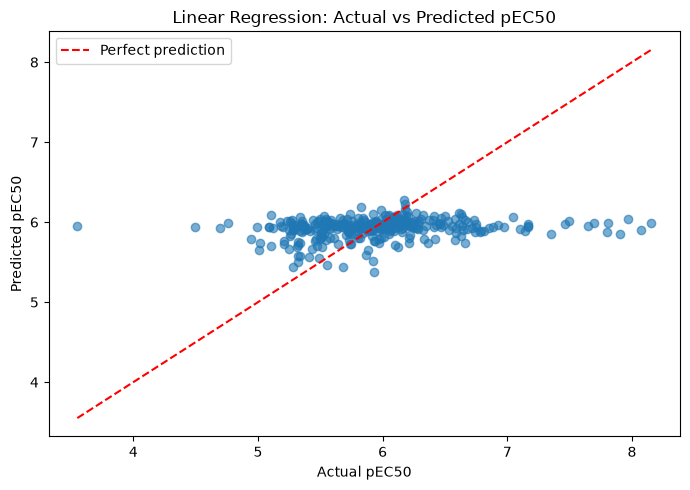

In [7]:
plt.figure(figsize=(7, 5))
plt.scatter(y_test, test_predictions, alpha=0.6)

# Line of perfect prediction
min_val = min(y_test.min(), test_predictions.min())
max_val = max(y_test.max(), test_predictions.max())

plt.plot(
    [min_val, max_val],
    [min_val, max_val],
    "r--",
    label="Perfect prediction"
)

plt.xlabel("Actual pEC50")
plt.ylabel("Predicted pEC50")
plt.title("Linear Regression: Actual vs Predicted pEC50")
plt.legend()
plt.tight_layout()
plt.show()

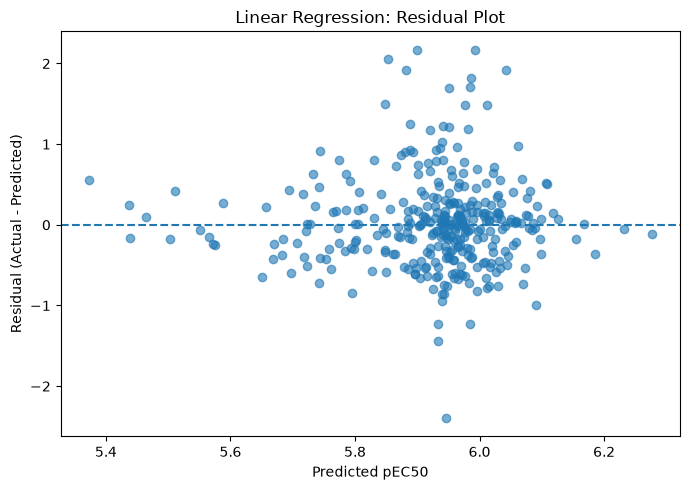

In [8]:
# Calculate residuals
residuals = y_test - test_predictions

plt.figure(figsize=(7, 5))
plt.scatter(test_predictions, residuals, alpha=0.6)
plt.axhline(y=0, linestyle="--")

plt.xlabel("Predicted pEC50")
plt.ylabel("Residual (Actual - Predicted)")
plt.title("Linear Regression: Residual Plot")
plt.tight_layout()
plt.show()

### Observations from Linear Regression Performance

1. **Low predictive performance:** The training R² (0.046) and testing R² (0.044) were both very low, showing that the model explained less than 5% of the variation in pEC50 values. The actual-versus-predicted plot also showed that most predictions were densed around pEC50 = 6, despite actual values ranging from approximately 3.5 to 8.2. This suggests that the model struggled to predict differences in antimalarial potency.

2. **Little evidence of overfitting:** The training and testing R² values were almost identical, while RMSE increased only slightly from 0.541 to 0.570. The MAE also increased from 0.386 to 0.403. This suggests that the model performed similarly on training and unseen data. Five-fold cross-validation supported this observation, with a mean R² of 0.022 and RMSE of 0.545, indicating consistently weak predictive performance rather than overfitting.

3. **Possible underfitting and model limitations:** The low R² values across training, cross-validation and testing suggest that Linear Regression may be too simple to predict antimalarial potency accurately. The residual analysis showed that the model tended to overpredict weak compounds and underpredict highly potent compounds. This may be because the nine molecular descriptors do not capture all the factors affecting biological activity. Overall, Linear Regression provides a useful baseline for comparison with more complex models that may better capture nonlinear relationships and improve prediction accuracy.